# 02 — Data Cleaning

Inspect missing observations, create lagged and cyclic features, and export model-ready datasets for **6-hour-ahead Hanoi PM2.5 forecasting**.

**Input:** `../data/interim/hanoi_air_quality_weather_hourly.pkl`  
**Output:** four `.pkl` datasets in `../data/processed/`.

## 1. Load and validate hourly data

In [12]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INTERIM_DIR = Path("../data/interim")
df_merged = pd.read_pickle(INTERIM_DIR / "hanoi_air_quality_weather_hourly.pkl")

# Consecutive rows must represent consecutive hours for lag/target shifts to be valid.
assert df_merged["timestamp_utc"].is_unique
assert df_merged["timestamp_utc"].is_monotonic_increasing
assert df_merged["timestamp_utc"].diff().iloc[1:].eq(pd.Timedelta(hours=1)).all()

print("Dataset shape:", df_merged.shape)

Dataset shape: (8760, 10)


/var/folders/sb/pmlt6jxs48zgnsjrc491m_s80000gn/T/ipykernel_91657/2778617111.py:13: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  assert df_merged["timestamp_utc"].diff().iloc[1:].eq(pd.Timedelta(hours=1)).all()


In [13]:
missing_summary = pd.DataFrame({
    "missing_count": df_merged.isna().sum(),
    "missing_pct": (
        df_merged.isna().mean() * 100
    ).round(2)
})

missing_summary

,missing_count,missing_pct
timestamp_utc,0,0.00
pm25,678,7.74
pm10,591,6.75
no2,1251,14.28
temperature_2m,0,0.00
relative_humidity_2m,0,0.00
precipitation,0,0.00
surface_pressure,0,0.00
wind_speed_10m,0,0.00
wind_direction_10m,0,0.00


## 2. Analyze missing-data gaps

In [14]:
def summarize_missing_gaps(df, column):
    is_missing = df[column].isna()
    gap_id = (is_missing != is_missing.shift()).cumsum()

    return (
        df[is_missing]
        .groupby(gap_id[is_missing])
        .agg(
            start=("timestamp_utc", "min"),
            end=("timestamp_utc", "max"),
            length_hours=("timestamp_utc", "size"),
        )
        .reset_index(drop=True)
    )

pollutants = ["pm25", "pm10", "no2"]
gap_tables = {
    pollutant: summarize_missing_gaps(df_merged, pollutant)
    for pollutant in pollutants
}

gap_summary = pd.DataFrame([
    {
        "variable": pollutant,
        "missing_hours": df_merged[pollutant].isna().sum(),
        "number_of_gaps": len(gaps),
        "median_gap_hours": gaps["length_hours"].median(),
        "longest_gap_hours": gaps["length_hours"].max(),
    }
    for pollutant, gaps in gap_tables.items()
])

gap_summary

,variable,missing_hours,number_of_gaps,median_gap_hours,longest_gap_hours
0,pm25,678,97,2.0,136
1,pm10,591,47,3.0,136
2,no2,1251,31,5.0,466


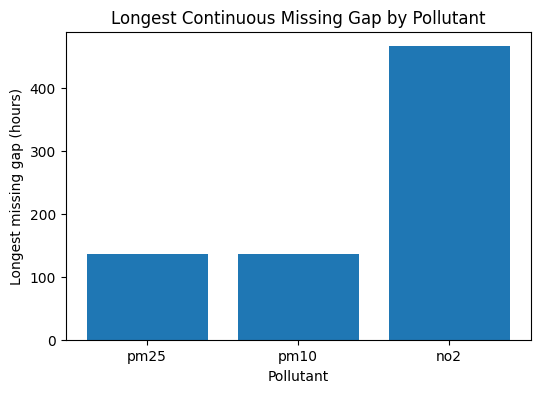

In [15]:
plt.figure(figsize=(6, 4))

plt.bar(
    gap_summary["variable"],
    gap_summary["longest_gap_hours"]
)

plt.xlabel("Pollutant")
plt.ylabel("Longest missing gap (hours)")
plt.title("Longest Continuous Missing Gap by Pollutant")

plt.show()

**Decision:** Keep missing pollutant observations as `NaN` rather than interpolate across potentially prolonged outages.

## 3. Engineer forecasting features

In [16]:
df_model = df_merged.copy()

df_model["pm25_lag1"] = df_model["pm25"].shift(1)
df_model["pm25_lag2"] = df_model["pm25"].shift(2)
df_model["pm25_lag3"] = df_model["pm25"].shift(3)
df_model["pm25_lag6"] = df_model["pm25"].shift(6)

df_model["pm25_t_plus_6"] = df_model["pm25"].shift(-6)

In [17]:
# Encode circular directions and local time of day.
wind_rad = np.deg2rad(df_model["wind_direction_10m"])
df_model["wind_dir_sin"] = np.sin(wind_rad)
df_model["wind_dir_cos"] = np.cos(wind_rad)

df_model["timestamp_local"] = df_model["timestamp_utc"].dt.tz_convert("Asia/Ho_Chi_Minh")
hour = df_model["timestamp_local"].dt.hour
df_model["hour_sin"] = np.sin(2 * np.pi * hour / 24)
df_model["hour_cos"] = np.cos(2 * np.pi * hour / 24)

## 4. Construct three feature sets

In [18]:
features_base = [
    "pm25",
    "pm25_lag1",
    "pm25_lag2",
    "pm25_lag3",
    "pm25_lag6",
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "surface_pressure",
    "wind_speed_10m",
    "wind_dir_sin",
    "wind_dir_cos",
    "hour_sin",
    "hour_cos"
]

features_pm10 = features_base + ["pm10"]

features_full = features_base + [
    "pm10",
    "no2"
]

In [19]:
target = "pm25_t_plus_6"

df_base = df_model.dropna(subset=features_base + [target]).copy()
df_pm10 = df_model.dropna(subset=features_pm10 + [target]).copy()
df_full = df_model.dropna(subset=features_full + [target]).copy()

print("All hourly rows:", len(df_model))
print("Base:", len(df_base))
print("Base + PM10:", len(df_pm10))
print("Full (Base + PM10 + NO2):", len(df_full))
print("Rows excluded from full set:", len(df_model) - len(df_full))

All hourly rows: 8760
Base: 7454
Base + PM10: 7450
Full (Base + PM10 + NO2): 6796
Rows excluded from full set: 1964


In [20]:
missing_required = (
    df_model[features_full + [target]]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

missing_required

no2                     1251
pm25_t_plus_6            684
pm25_lag6                683
pm25_lag3                681
pm25_lag2                680
pm25_lag1                679
pm25                     678
pm10                     591
precipitation              0
relative_humidity_2m       0
wind_speed_10m             0
wind_dir_sin               0
wind_dir_cos               0
hour_sin                   0
hour_cos                   0
temperature_2m             0
surface_pressure           0
dtype: int64

## 5. Validate and save datasets

In [21]:
target_check = df_model["pm25_t_plus_6"].equals(df_model["pm25"].shift(-6))
assert target_check, "The 6-hour-ahead target is misaligned."
print("6-hour target alignment:", target_check)

6-hour target alignment: True


In [22]:
PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

df_model.to_pickle(PROCESSED_DIR / "hanoi_pm25_model_withna.pkl")
df_base.to_pickle(PROCESSED_DIR / "hanoi_pm25_model_base.pkl")
df_pm10.to_pickle(PROCESSED_DIR / "hanoi_pm25_model_pm10.pkl")
df_full.to_pickle(PROCESSED_DIR / "hanoi_pm25_model_full.pkl")

print("Saved 4 datasets to:", PROCESSED_DIR)

Saved 4 datasets to: ../data/processed
